# Business Problem 

A global e-commerce company operating across multiple regions manages end-to-end order fulfillment, including shipping and delivery, for products like sporting
goods. The company is facing inconsistent delivery performance, where actual shipping times often from schelduled timelines, leading to data to late deliveries and
unpredictable order profitablity.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as ticker
import matplotlib.cm as cm
from warnings import filterwarnings
filterwarnings('ignore')

In [4]:
#set professional color_theme
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("viridis")

viridis_colors = cm.viridis(np.linspace(0,1,5))
primary_color = viridis_colors[0]
secondary_color = viridis_colors[1]
accent_color = viridis_colors[2]
danger_color = '#800000'
neutral_color = viridis_colors[4]
custom_palette = viridis_colors

In [7]:
df = pd.read_csv('DataCoSupplyChainDataset.csv', encoding='latin-1')

In [8]:
df.head()

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


# Exploratory Data Analysis (EDA)

In [14]:
# overview
print('rows,cols:',df.shape)
print('\ncolumns:')
print(df.columns.tolist())
print('\nNum duplicates:' , df.duplicated().sum())
print('\nMissing values (top 20):')
print(df.isna().sum().sort_values(ascending=False).head(20))

rows,cols: (180519, 53)

columns:
['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Delivery Status', 'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City', 'Customer Country', 'Customer Email', 'Customer Fname', 'Customer Id', 'Customer Lname', 'Customer Password', 'Customer Segment', 'Customer State', 'Customer Street', 'Customer Zipcode', 'Department Id', 'Department Name', 'Latitude', 'Longitude', 'Market', 'Order City', 'Order Country', 'Order Customer Id', 'order date (DateOrders)', 'Order Id', 'Order Item Cardprod Id', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Id', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Order Item Total', 'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status', 'Order Zipcode', 'Product Card Id', 'Product Category Id', 'Product Description', 'Product Image', 'Product Name', 'Product Price', 'Product

In [18]:

# Data Cleaning

columns_to_drop = [
    'Product Description',
    'Product Image',
    'Customer Email',
    'Customer Password',
    'Customer Fname',
    'Customer Lname',
    'Customer Zipcode',
    'Customer Street',
    'Order Zipcode',
    'Longitude',
    'Latitude',
    'Order Item Cardprod Id',
    'Order Item Discount',
    'Order Item Discount Rate',
    'Order Item Id',
    'Order Item Product Price',
    'Category Id',
    'Department Id',
    'Order Id',
    'Order Customer Id',
    'Customer Id',
    'Product Card Id',
    'Product Category Id',
    'Benefit per order',
    'Product Status',
    'Customer City',
    'Order City',
    'Order Country',
    'Order State',
    'Customer State',
    'Market'
]

# Drop irrelevant, redundant, or unnecessary columns
# errors='ignore' prevents errors if a column is absent
df = df.drop(columns=columns_to_drop, errors='ignore')

# Remove canceled orders for delivery time analysis
df = df[df['Delivery Status'] != 'Shipping canceled'].copy()

# Convert date columns to datetime format
date_columns = [
    'order date (DateOrders)',
    'shipping date (DateOrders)'
]

for col in date_columns:
    df[col] = pd.to_datetime(df[col], errors='coerce')

# Check the dataset after cleaning
print('Rows, Columns:', df.shape)

print('\nColumns:')
print(df.columns.tolist())

print('\nNumber of Duplicate Rows:', df.duplicated().sum())

print('\nMissing Values (Top 20):')
print(df.isna().sum().sort_values(ascending=False).head(20))


Rows, Columns: (172765, 22)

Columns:
['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)', 'Sales per customer', 'Delivery Status', 'Late_delivery_risk', 'Category Name', 'Customer Country', 'Customer Segment', 'Department Name', 'order date (DateOrders)', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Order Item Total', 'Order Profit Per Order', 'Order Region', 'Order Status', 'Product Name', 'Product Price', 'shipping date (DateOrders)', 'Shipping Mode']

Number of Duplicate Rows: 0

Missing Values (Top 20):
Type                          0
Days for shipping (real)      0
shipping date (DateOrders)    0
Product Price                 0
Product Name                  0
Order Status                  0
Order Region                  0
Order Profit Per Order        0
Order Item Total              0
Sales                         0
Order Item Quantity           0
Order Item Profit Ratio       0
order date (DateOrders)       0
Department Name               0
Custom

In [19]:
df.head()

,Type,Days for shipping (real),Days for shipment (scheduled),Sales per customer,Delivery Status,Late_delivery_risk,Category Name,Customer Country,Customer Segment,Department Name,...,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order Status,Product Name,Product Price,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,314.640015,Advance shipping,0,Sporting Goods,Puerto Rico,Consumer,Fitness,...,1,327.75,314.640015,91.250000,Southeast Asia,COMPLETE,Smart watch,327.75,2018-02-03 22:56:00,Standard Class
1,TRANSFER,5,4,311.359985,Late delivery,1,Sporting Goods,Puerto Rico,Consumer,Fitness,...,1,327.75,311.359985,-249.089996,South Asia,PENDING,Smart watch,327.75,2018-01-18 12:27:00,Standard Class
2,CASH,4,4,309.720001,Shipping on time,0,Sporting Goods,EE. UU.,Consumer,Fitness,...,1,327.75,309.720001,-247.779999,South Asia,CLOSED,Smart watch,327.75,2018-01-17 12:06:00,Standard Class
3,DEBIT,3,4,304.809998,Advance shipping,0,Sporting Goods,EE. UU.,Home Office,Fitness,...,1,327.75,304.809998,22.860001,Oceania,COMPLETE,Smart watch,327.75,2018-01-16 11:45:00,Standard Class
4,PAYMENT,2,4,298.250000,Advance shipping,0,Sporting Goods,Puerto Rico,Corporate,Fitness,...,1,327.75,298.250000,134.210007,Oceania,PENDING_PAYMENT,Smart watch,327.75,2018-01-15 11:24:00,Standard Class


In [20]:
#value counts for categorical colums with low cardinality
for col in df.columns:
    if df[col].nunique() < 10:
        print(f'\n{col} value counts:')
        print(df[col].value_counts())


Type value counts:
Type
DEBIT       69295
TRANSFER    42129
PAYMENT     41725
CASH        19616
Name: count, dtype: int64

Days for shipping (real) value counts:
Days for shipping (real)
2    54205
6    27489
3    27478
4    27297
5    27003
0     4839
1     4454
Name: count, dtype: int64

Days for shipment (scheduled) value counts:
Days for shipment (scheduled)
4    103153
2     33806
1     26513
0      9293
Name: count, dtype: int64

Delivery Status value counts:
Delivery Status
Late delivery       98977
Advance shipping    41592
Shipping on time    32196
Name: count, dtype: int64

Late_delivery_risk value counts:
Late_delivery_risk
1    98977
0    73788
Name: count, dtype: int64

Customer Country value counts:
Customer Country
EE. UU.        106425
Puerto Rico     66340
Name: count, dtype: int64

Customer Segment value counts:
Customer Segment
Consumer       89420
Corporate      52528
Home Office    30817
Name: count, dtype: int64

Order Item Quantity value counts:
Order Item Quant

In [21]:

# Calculating order processing time and delivery delay

# Ensure date columns are in datetime format
df['order date (DateOrders)'] = pd.to_datetime(
    df['order date (DateOrders)'], errors='coerce'
)

df['shipping date (DateOrders)'] = pd.to_datetime(
    df['shipping date (DateOrders)'], errors='coerce'
)

# 1. Calculate order processing time in days
df['Order Processing Time'] = (
    df['shipping date (DateOrders)'] -
    df['order date (DateOrders)']
).dt.total_seconds() / (24 * 60 * 60)

# 2. Calculate delivery delay in days
df['Delay'] = (
    df['Order Processing Time'] -
    df['Days for shipment (scheduled)']
)

# 3. Identify delayed orders
df['Is_Delayed'] = df['Delay'] > 0

# 4. Extract date and time features from order date
order_date = df['order date (DateOrders)']

df['order_year'] = order_date.dt.year
df['order_month'] = order_date.dt.month
df['order_day'] = order_date.dt.day
df['order_hour'] = order_date.dt.hour

df.describe()


,Days for shipping (real),Days for shipment (scheduled),Sales per customer,Late_delivery_risk,order date (DateOrders),Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Product Price,shipping date (DateOrders),Order Processing Time,Delay,order_year,order_month,order_day,order_hour
count,172765.000000,172765.000000,172765.000000,172765.000000,172765,172765.000000,172765.000000,172765.000000,172765.000000,172765.000000,172765.000000,172765,172765.000000,172765.000000,172765.000000,172765.000000,172765.000000,172765.000000
mean,3.498596,2.933100,183.165948,0.572900,2016-06-12 15:25:39.457991936,0.120801,2.127694,203.828493,183.165948,22.032360,141.278595,2016-06-16 03:25:14.452927488,3.499711,0.566611,2015.970874,6.235511,15.739803,11.482604
min,0.000000,0.000000,7.490000,0.000000,2015-01-01 00:00:00,-2.750000,1.000000,9.990000,7.490000,-4274.979980,9.990000,2015-01-03 00:00:00,0.500000,-2.000000,2015.000000,1.000000,1.000000,0.000000
25%,2.000000,2.000000,104.379997,0.000000,2015-09-21 18:01:00,0.080000,1.000000,119.980003,104.379997,7.030000,50.000000,2015-09-25 08:59:00,2.000000,0.000000,2015.000000,3.000000,8.000000,5.000000
50%,3.000000,4.000000,163.990005,1.000000,2016-06-11 08:11:00,0.270000,1.000000,199.919998,163.990005,31.520000,59.990002,2016-06-15 03:38:00,3.000000,1.000000,2016.000000,6.000000,16.000000,11.000000
75%,5.000000,4.000000,247.399994,1.000000,2017-02-28 21:08:00,0.360000,3.000000,299.950012,247.399994,64.800003,199.990005,2017-03-04 08:00:00,5.000000,1.000000,2017.000000,9.000000,23.000000,17.000000
max,6.000000,4.000000,1939.989990,1.000000,2018-01-31 23:38:00,0.500000,5.000000,1999.989990,1939.989990,911.799988,1999.989990,2018-02-06 22:14:00,6.000000,4.000000,2018.000000,12.000000,31.000000,23.000000
std,1.623446,1.373405,120.141871,0.494659,NaN,0.466610,1.453663,132.392520,120.141871,104.355313,139.862956,NaN,1.617234,1.488683,0.829255,3.405593,8.823467,6.927276


In [22]:
df['Order Profit Per Order'] > 0 

0          True
1         False
2         False
3          True
4          True
          ...  
180514     True
180515    False
180516     True
180517     True
180518     True
Name: Order Profit Per Order, Length: 172765, dtype: bool

In [23]:

# Profitability Flag based on Order Profit Per Order

df['Profitability Flag'] = np.where(
    df['Order Profit Per Order'] > 0,
    'Profit',
    np.where(
        df['Order Profit Per Order'] < 0,
        'Loss',
        'Break-even'
    )
)

# Count the number of orders in each profitability category
print(df['Profitability Flag'].value_counts())

# Display sample records
print(df[['Order Profit Per Order', 'Profitability Flag']].head())


Profitability Flag
Profit        139354
Loss           32295
Break-even      1116
Name: count, dtype: int64
   Order Profit Per Order Profitability Flag
0               91.250000             Profit
1             -249.089996               Loss
2             -247.779999               Loss
3               22.860001             Profit
4              134.210007             Profit


In [26]:
df['Profitability Flag'].value_counts(normalize=True)

Profitability Flag
Profit        0.80661
Loss          0.18693
Break-even    0.00646
Name: proportion, dtype: float64

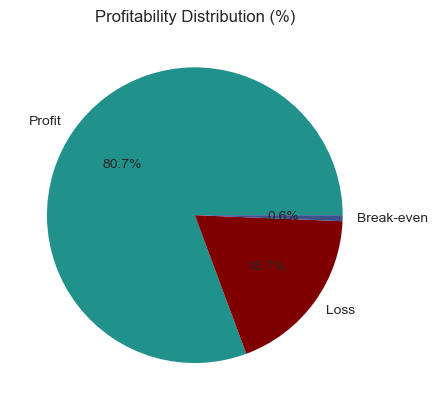

In [27]:
#visualization of profitability distribution
profit_counts = df['Profitability Flag'].value_counts(normalize=True) * 100
profit_counts.plot(kind = 'pie' , autopct='%1.1f%%', colors=[accent_color,danger_color,secondary_color])
plt.ylabel('')
plt.title('Profitability Distribution (%)')
plt.show()

In [28]:
def format_func(value):
    if value >= 1e6:
        return f'{value/1e6:.1f}M $'
    elif value >= 1e3:
        return f'{value/1e3:.1f}K $'
    else:
        return f'{value:.0f} $'

delayed_df = df[df['Delay'] > 0]
metrics = {}
metrics['Total Orders'] = len(df)
metrics['Late Deliveries'] = len(delayed_df)
metrics['90% Delay (days)'] = delayed_df['Delay'].quantile(0.90)
metrics['On time Delivery %'] = (1 - float(metrics['Late Deliveries']) / metrics['Total Orders']) * 100
metrics['Late Delivery %'] = float(metrics['Late Deliveries']) / metrics['Total Orders'] * 100
metrics['Total Profit'] = format_func(df.loc[df['Order Profit Per Order'] > 0, 'Order Profit Per Order'].sum())
metrics['Total Loss due to delays'] = format_func(df.loc[df['Delay'] > 0, 'Order Profit Per Order'].sum())

print('\n--- Business KPIs ---\n')
for k, v in metrics.items():
    if isinstance(v, float):
        print(f"{k}: {v:.2f}")
    else:
        print(f"{k}: {v}")


--- Business KPIs ---

Total Orders: 172765
Late Deliveries: 103816
90% Delay (days): 3.00
On time Delivery %: 39.91
Late Delivery %: 60.09
Total Profit: 7.5M $
Total Loss due to delays: 2.2M $


# Profitability vs Delivery Time Analysis

In [29]:
profit_metrics = (
    df.groupby('Delay')['Order Profit Per Order']
        .agg(
            mean_profit = 'mean',
            total_profit = 'sum' ,
            order_count = 'count'
        ).reset_index()
)

In [30]:
profit_metrics

,Delay,mean_profit,total_profit,order_count
0,-2.0,23.360134,4.875961e+05,20873
1,-1.0,21.604769,4.476292e+05,20719
2,0.0,22.708925,6.212481e+05,27357
3,0.5,20.895527,1.941821e+05,9293
4,1.0,22.333227,1.194895e+06,53503
5,2.0,21.128491,5.821110e+05,27551
6,3.0,20.031412,1.356527e+05,6772
7,4.0,21.368783,1.431067e+05,6697


In [31]:
delay_distribution = (
    df['Delay']
    .value_counts(normalize=True)   # share of orders per delay value
    .sort_index()                   # order by delay: -2, -1, 0, 1, 2...
    * 100                           # convert share to %
).reset_index()                     # turn into a DataFrame

In [32]:
delay_distribution

,Delay,proportion
0,-2.0,12.081730
1,-1.0,11.992591
2,0.0,15.834805
3,0.5,5.378983
4,1.0,30.968657
5,2.0,15.947096
6,3.0,3.919775
7,4.0,3.876364



Profit Metrics by Delay Day:


,Delay,mean_profit,total_profit,order_count
0,-2.0,23.4,487596.1,20873
1,-1.0,21.6,447629.2,20719
2,0.0,22.7,621248.1,27357
3,0.5,20.9,194182.1,9293
4,1.0,22.3,1194894.7,53503
5,2.0,21.1,582111.0,27551
6,3.0,20.0,135652.7,6772
7,4.0,21.4,143106.7,6697



Delay Distribution (%):


,Delay_Days,Percentage
0,-2.0,12.081730
1,-1.0,11.992591
2,0.0,15.834805
3,0.5,5.378983
4,1.0,30.968657
5,2.0,15.947096
6,3.0,3.919775
7,4.0,3.876364


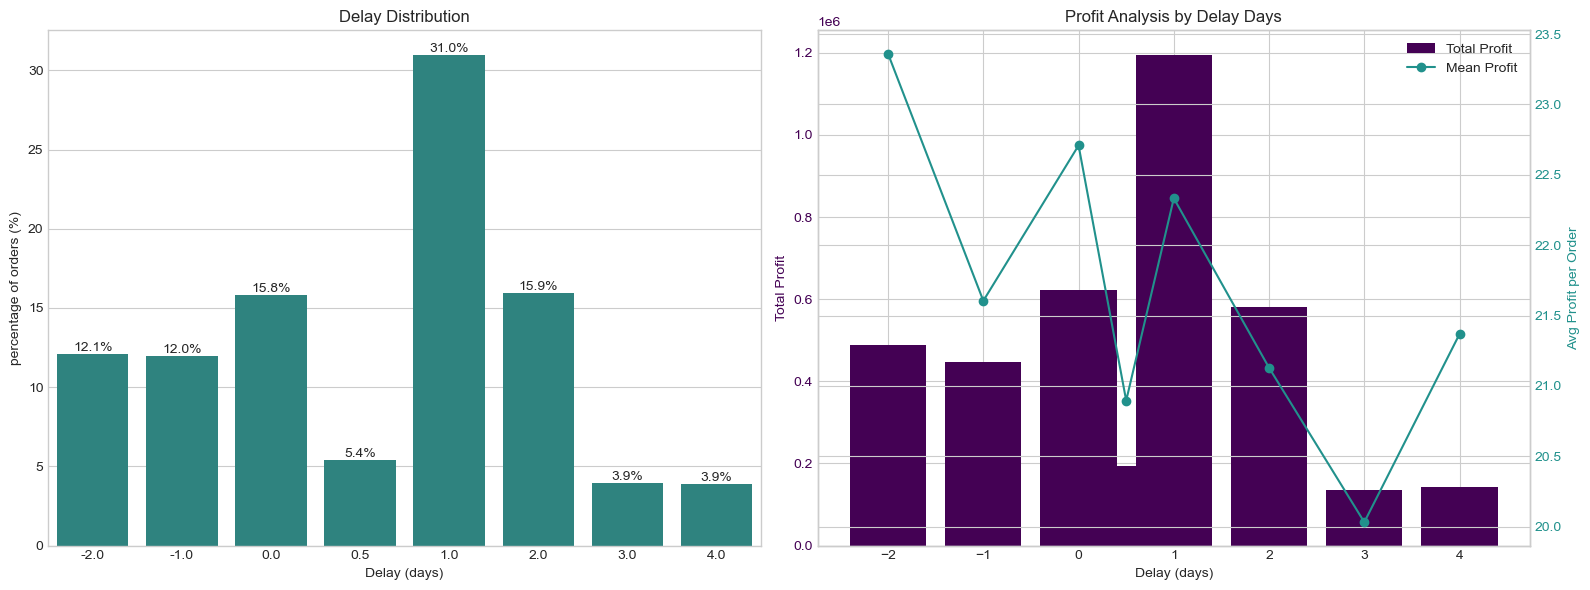

In [36]:
delay_distribution.columns = ['Delay_Days', 'Percentage']

print("\nProfit Metrics by Delay Day:")
display(profit_metrics.round(1))

print("\nDelay Distribution (%):")
display(delay_distribution)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# First subplot: Delay Distribution
sns.barplot(x='Delay_Days', y='Percentage', data=delay_distribution, color=accent_color, ax=ax1)
ax1.set_title('Delay Distribution')
ax1.set_xlabel('Delay (days)')
ax1.set_ylabel('percentage of orders (%)')

# percentage text on bars
for bar in ax1.patches:
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width() / 2, height,
             f'{height:.1f}%', ha='center', va='bottom')

# Second subplot: Profit Analysis by Delay Days
ax2.set_ylabel('Total Profit', color=primary_color)
ax2.bar(profit_metrics['Delay'], profit_metrics['total_profit'],
        color=primary_color, label='Total Profit')
ax2.tick_params(axis='y', labelcolor=primary_color)
ax2.set_xlabel('Delay (days)')
ax2.set_title('Profit Analysis by Delay Days')

# Second y-axis: average profit per order (assumed column, see note below)
ax3 = ax2.twinx()
ax3.plot(profit_metrics['Delay'], profit_metrics['mean_profit'],
         color=accent_color, marker='o', label='Mean Profit')
ax3.set_ylabel('Avg Profit per Order', color=accent_color)
ax3.tick_params(axis='y', labelcolor=accent_color)

# Combined legend
lines1, labels1 = ax2.get_legend_handles_labels()
lines2, labels2 = ax3.get_legend_handles_labels()
ax2.legend(lines1 + lines2, labels1 + labels2, loc='upper right')

plt.tight_layout()
plt.show()

# Bottleneck Detection

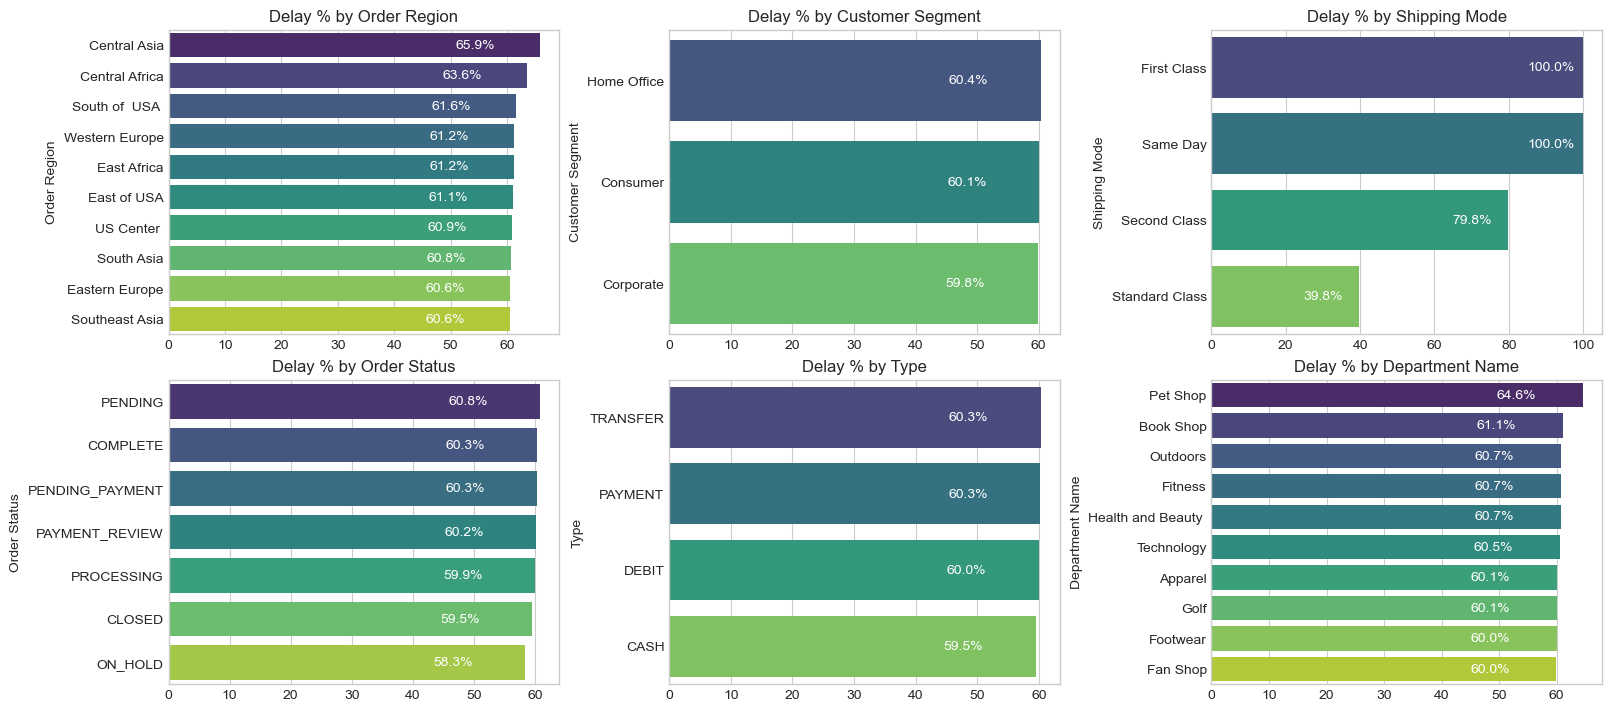

In [40]:
def compute_delay_pct_by_category(category):
    cat_df = df.groupby(category).agg(
        total_orders=('Delay', 'count'),
        late_orders=('Is_Delayed', 'sum')
    ).reset_index()
    cat_df['delay_pct'] = cat_df['late_orders'] / cat_df['total_orders'] * 100
    cat_df = cat_df.sort_values('delay_pct', ascending=False).head(10)
    return cat_df

categories = ['Order Region', 'Customer Segment', 'Shipping Mode',
              'Order Status', 'Type', 'Department Name']

fig, axes = plt.subplots(2, 3, figsize=(16, 7), constrained_layout=True)
axes = axes.flatten()

for ax, category in zip(axes, categories):
    cat_df = compute_delay_pct_by_category(category)
    sns.barplot(
        data=cat_df,
        x='delay_pct',
        y=category,
        ax=ax,
        palette='viridis'
    )
    ax.set_title(f'Delay % by {category}')
    ax.set_xlabel('')
    ax.set_ylabel(category)

    # % label at the end of each bar
    for i,row in cat_df.reset_index().iterrows():
        ax.text(row['delay_pct'] -15, i, f"{row['delay_pct']:.1f}%", va='center',fontsize=10,color = 'white')
        

plt.show()

# Root Cause Analysis

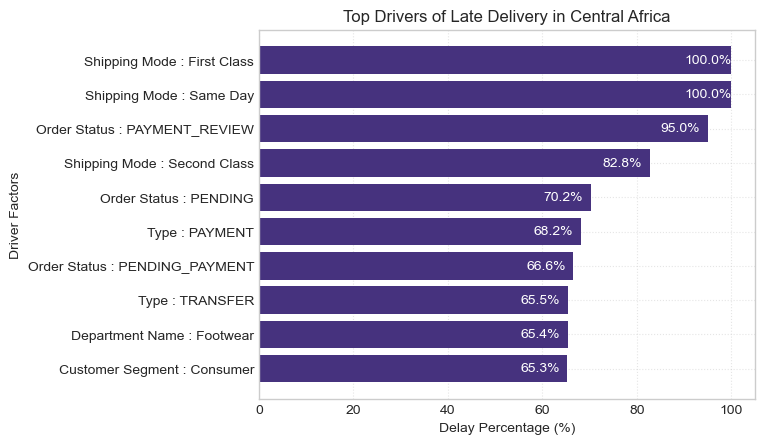

In [43]:
# Top drivers of late delivery by region

def top_drivers_for_region(region):
    df_region = df[df['Order Region'] == region].copy()

    drivers = ['Shipping Mode', 'Customer Segment', 'Department Name', 'Type', 'Order Status']

    all_factors = []
    for factor in drivers:
        temp = (
            df_region.groupby(factor)
            .agg(
                total_orders=('Delay', 'count'),
                late_orders=('Is_Delayed', 'sum'),
                avg_delay=('Delay', 'mean')
            )
            .reset_index()
        )

        temp['delay_pct'] = temp['late_orders'] / temp['total_orders'] * 100
        temp['Driver'] = factor
        temp['Factor_Level'] = factor + " : " + temp[factor].astype(str)

        all_factors.append(temp[['Driver', 'Factor_Level', 'delay_pct', 'avg_delay', 'total_orders']])

    # Combine all drivers
    final_df = pd.concat(all_factors)

    # Top 10 drivers
    top_factors = final_df.sort_values('delay_pct', ascending=False).head(10)
    plt.figure()

    bars = plt.barh(top_factors['Factor_Level'], top_factors['delay_pct'])

    plt.xlabel("Delay Percentage (%)")
    plt.ylabel("Driver Factors")
    plt.title(f"Top Drivers of Late Delivery in {region}")
    plt.grid(True, linestyle=':', alpha=0.5)
    plt.gca().invert_yaxis()

    for bar in bars:
        width = bar.get_width()
        plt.text(width - 10, bar.get_y() + bar.get_height()/2,
                 f"{width:.1f}%",
                 va='center', fontsize=10, color='white')

    plt.show()

top_drivers_for_region('Central Africa')

# Time-Based Analysis

In [44]:
# Delay % by Month, Day of Week, Hour

delay_by_month = (
    df.groupby('order_month')['Is_Delayed']
      .mean()
      .reset_index()
)
delay_by_month['delay_pct'] = delay_by_month['Is_Delayed'] * 100

delay_by_day = (
    df.groupby('order_day')['Is_Delayed']
      .mean()
      .reset_index()
)
delay_by_day['delay_pct'] = delay_by_day['Is_Delayed'] * 100

delay_by_hour = (
    df.groupby('order_hour')['Is_Delayed']
      .mean()
      .reset_index()
)
delay_by_hour['delay_pct'] = delay_by_hour['Is_Delayed'] * 100

Days found: ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']


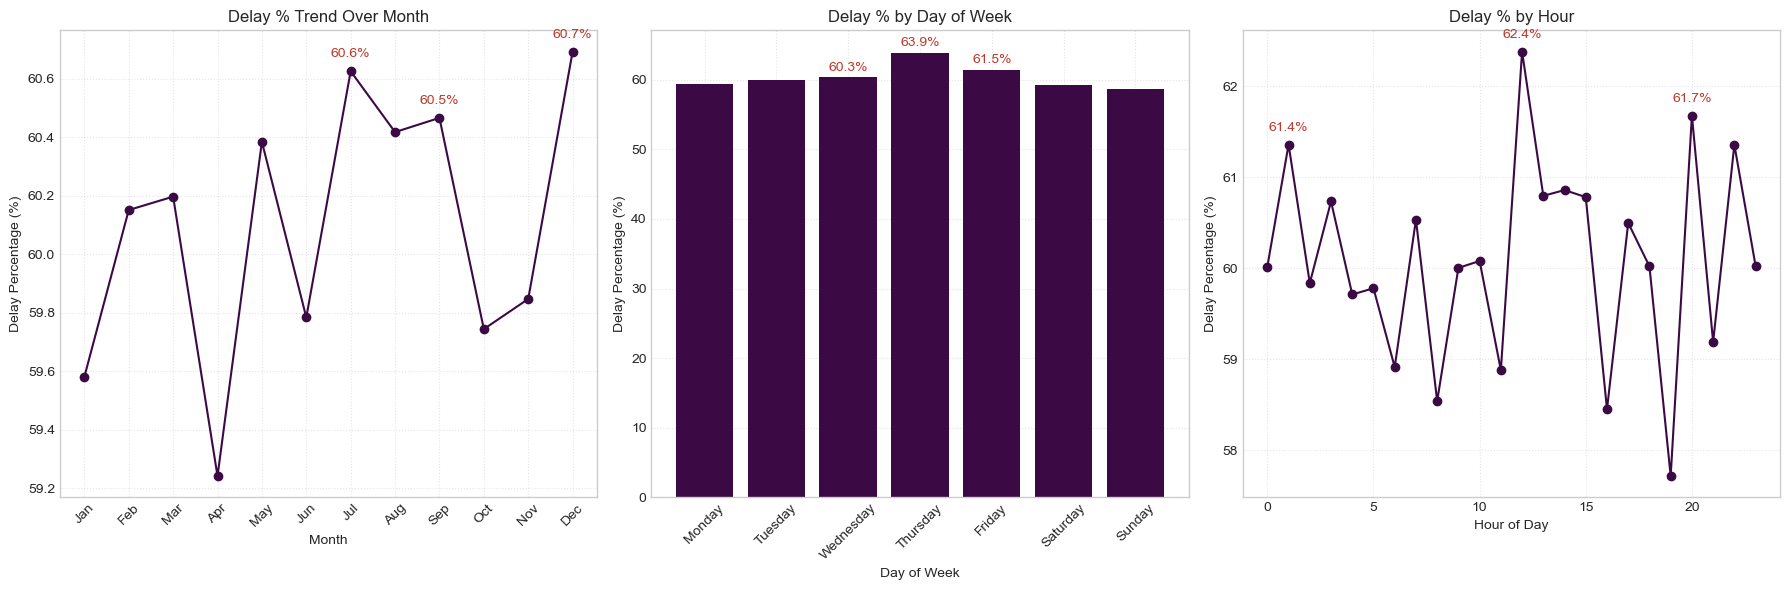

In [49]:

primary_color = '#3b0a45'   # change if you defined your own earlier
danger_color  = '#c0392b'

# ---------- Build delay tables ----------
delay_by_month = df.groupby('order_month')['Is_Delayed'].mean().reset_index()
delay_by_month['delay_pct'] = delay_by_month['Is_Delayed'] * 100

delay_by_hour = df.groupby('order_hour')['Is_Delayed'].mean().reset_index()
delay_by_hour['delay_pct'] = delay_by_hour['Is_Delayed'] * 100

delay_by_day = df.groupby('order_day')['Is_Delayed'].mean().reset_index()
delay_by_day['delay_pct'] = delay_by_day['Is_Delayed'] * 100

# ---------- Fix day labels (handles 0–6, 1–7, or text) ----------
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
s = delay_by_day['order_day']

if pd.api.types.is_numeric_dtype(s):
    start = 1 if s.min() == 1 else 0                       # 1–7 or 0–6
    num_map = {i + start: d for i, d in enumerate(day_order)}
    s = s.map(num_map)
else:
    short_map = {d[:3]: d for d in day_order}
    s = s.astype(str).str.strip().str.title().str[:3].map(short_map)

delay_by_day['order_day'] = pd.Categorical(s, categories=day_order, ordered=True)
delay_by_day = delay_by_day.dropna(subset=['order_day']).sort_values('order_day')
delay_by_day['order_day'] = delay_by_day['order_day'].astype(str)

print("Days found:", list(delay_by_day['order_day']))   # should list all 7

# ---------- Plot ----------
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 6))

# Subplot 1: Month
ax1.plot(delay_by_month['order_month'], delay_by_month['delay_pct'], marker='o', color=primary_color)
ax1.set_xticks(range(1, 13))
ax1.set_xticklabels(['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'], rotation=45)
ax1.set_xlabel("Month")
ax1.set_ylabel("Delay Percentage (%)")
ax1.set_title("Delay % Trend Over Month")
ax1.grid(True, linestyle=':', alpha=0.5)

for _, row in delay_by_month.nlargest(3, 'delay_pct').iterrows():
    ax1.annotate(f"{row['delay_pct']:.1f}%", (row['order_month'], row['delay_pct']),
                 textcoords="offset points", xytext=(0,10), ha='center', fontsize=10, color=danger_color)

# Subplot 2: Day of Week
ax2.bar(delay_by_day['order_day'], delay_by_day['delay_pct'], color=primary_color)
ax2.tick_params(axis='x', rotation=45)
ax2.set_xlabel("Day of Week")
ax2.set_ylabel("Delay Percentage (%)")
ax2.set_title("Delay % by Day of Week")
ax2.grid(True, linestyle=':', alpha=0.5)

for _, row in delay_by_day.nlargest(3, 'delay_pct').iterrows():
    height = row['delay_pct']
    ax2.text(row['order_day'], height + 0.5, f'{height:.1f}%',
             ha='center', va='bottom', fontsize=10, color=danger_color)

# Subplot 3: Hour
ax3.plot(delay_by_hour['order_hour'], delay_by_hour['delay_pct'], marker='o', color=primary_color)
ax3.set_xlabel("Hour of Day")
ax3.set_ylabel("Delay Percentage (%)")
ax3.set_title("Delay % by Hour")
ax3.grid(True, linestyle=':', alpha=0.5)

for _, row in delay_by_hour.nlargest(3, 'delay_pct').iterrows():
    ax3.annotate(f"{row['delay_pct']:.1f}%", (row['order_hour'], row['delay_pct']),
                 textcoords="offset points", xytext=(0,10), ha='center', fontsize=10, color=danger_color)

plt.tight_layout()
plt.show()

# Machine Learning Modelling

In [50]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, classification_report
from sklearn.ensemble import RandomForestClassifier
from collections import Counter
from imblearn.over_sampling import SMOTE

# Features and target
X = df[['Type', 'Days for shipment (scheduled)', 'Category Name', 'Customer Segment',
        'Department Name', 'Order Region', 'Shipping Mode',
        'order_month', 'order_day', 'order_hour']]      # last 3 = my completion (cut off)
y = df['Late_delivery_risk']



In [51]:
cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()
print('Categorical columns:', cat_cols)

# Frequency encoding (low-dimensional and robust for high-cardinality)
for col in cat_cols:
    freq = X[col].value_counts(normalize=True)
    X[f'{col}_freq'] = X[col].map(freq)

# Keep numeric columns + new encoded features, drop original string categories
X_encoded = X.drop(columns=cat_cols)
print('Shape after freq+target encoding:', X_encoded.shape)

# use encoded features for modeling
X = X_encoded

# train/test split after encoding
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

Categorical columns: ['Type', 'Category Name', 'Customer Segment', 'Department Name', 'Order Region', 'Shipping Mode']
Shape after freq+target encoding: (172765, 10)


In [52]:
# Balancing the training data using SMOTE
print("Before balancing (train):", Counter(y_train))

smote = SMOTE(random_state=42)
X_train_bal, y_train_bal = smote.fit_resample(X_train, y_train)

print("After balancing (train):", Counter(y_train_bal))

Before balancing (train): Counter({1: 79182, 0: 59030})
After balancing (train): Counter({0: 79182, 1: 79182})


In [53]:
def evaluate_model(y_true, y_pred, model_name):
    print(f"\n--- {model_name} ---")
    print("Accuracy:", round(accuracy_score(y_true, y_pred), 2))
    print("Precision:", round(precision_score(y_true, y_pred), 2))
    print("Recall:", round(recall_score(y_true, y_pred), 2))
    print("\nClassification Report:\n", classification_report(y_true, y_pred))

# Fit the Random Forest model on balanced data
rf_model_balanced = RandomForestClassifier(random_state=42)
rf_model_balanced.fit(X_train_bal, y_train_bal)

y_pred_rf_balanced = rf_model_balanced.predict(X_test)

evaluate_model(y_test, y_pred_rf_balanced, "Random Forest Classifier")


--- Random Forest Classifier ---
Accuracy: 0.77
Precision: 0.83
Recall: 0.76

Classification Report:
               precision    recall  f1-score   support

           0       0.71      0.79      0.75     14758
           1       0.83      0.76      0.79     19795

    accuracy                           0.77     34553
   macro avg       0.77      0.77      0.77     34553
weighted avg       0.78      0.77      0.77     34553

